# Stage 2: Split the four datasets

**Stage:** 2 (split) · **Runs on:** Kaggle and locally

| | |
|---|---|
| Input | `liar_cleaned.csv`, `welfake_cleaned.csv`, `covid_cleaned.csv`, `fakenewsnet_cleaned.csv` (Stage 1) |
| Output (classification) | `<dataset>_train.csv`, `<dataset>_val.csv`, `<dataset>_test.csv` for liar, welfake, covid, fakenewsnet (12 files) |
| Output (regression) | `liar_reg_train.csv`, `liar_reg_val.csv`, `liar_reg_test.csv` (3 files) |

Each dataset is split **on its own** (70% train / 15% validation / 15% test), because every model
is trained once per dataset in Stage 5.

Steps:
1. Remove texts that appear in **more than one** dataset, so a model is never tested on another
   dataset with a text it was trained on.
2. Limit WELFake's size (training time) and balance GossipCop's classes.
3. Split LIAR **once**, by its 0–5 score, and use that split for both regression and classification.
4. Split the other three datasets by label.
5. Check for leaks and save.

**Validation** is for choosing models and training the ensemble (Stages 5–6).
**Test** is only used in Stage 7.

**On Kaggle:** add the four Stage 1 notebooks (01a–01d) as inputs
(**Add Input → Your Work → Notebooks**) and attach the `misinfo_utils` utility script.

In [7]:
# Setup: import the shared code. Works on Kaggle and locally.
import sys
from pathlib import Path

# Locally, misinfo_utils.py is in <project>/src/. On Kaggle it is an attached Utility Script,
# so this loop finds nothing and the import below still works.
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "src" / "misinfo_utils.py").exists():
        sys.path.insert(0, str(folder / "src"))
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import misinfo_utils as mu

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 100)
paths = mu.setup("02")

misinfo_utils | stage 02 | running on local
  read from : D:\misinfo-project\data\raw, D:\misinfo-project\outputs
  write to  : D:\misinfo-project\outputs\02_split


In [8]:
WELFAKE_MAX_ROWS = 20000    # WELFake has ~63k long articles; cap it to keep training time reasonable.
                            # None = keep all rows.
BALANCE_GOSSIPCOP = True    # GossipCop has ~3x more real than fake headlines; True = downsample real to match fake

# When the same text is in two datasets, it is KEPT in the dataset that comes first in this list
# and removed from the others. LIAR is first because its rows are also needed for regression;
# WELFake is last because it has by far the most rows to spare.
DEDUP_ORDER = ["liar", "covid", "fakenewsnet", "welfake"]

## 1. Load the cleaned datasets

In [9]:
data = {ds: mu.read_csv(mu.cleaned_file(ds)) for ds in mu.DATASETS}

loaded = pd.DataFrame({
    ds: {"rows": len(df),
         "reliable (0)": int((df["label"] == 0).sum()),
         "misleading (1)": int((df["label"] == 1).sum()),
         "no label (LIAR half-true)": int(df["label"].isna().sum())}
    for ds, df in data.items()}).T
loaded

,rows,reliable (0),misleading (1),no label (LIAR half-true)
liar,12791,4522,5641,2628
welfake,63313,34514,28799,0
covid,10280,5484,4796,0
fakenewsnet,21221,16106,5115,0


## 2. Remove texts that appear in more than one dataset

Stage 1 already removed duplicates **inside** each dataset. Here the four datasets are compared
with each other (LIAR and FakeNewsNet's PolitiFact part come from the same fact-checking site).
Texts are compared in a normalised form (lowercase, letters and digits only).

In [10]:
stacked = pd.concat([data[ds] for ds in DEDUP_ORDER], ignore_index=True)
stacked["key"] = stacked["text"].map(mu.dedup_key)

is_copy = stacked.duplicated("key", keep="first")          # True for the 2nd, 3rd ... appearance
kept_in = stacked.loc[~is_copy].set_index("key")["source_dataset"]
removed = stacked.loc[is_copy].assign(kept_in=lambda d: d["key"].map(kept_in))

print(f"Texts found in more than one dataset: {len(removed):,} rows removed")
if len(removed):
    display(pd.crosstab(removed["source_dataset"], removed["kept_in"],
                        rownames=["removed from"], colnames=["kept in"]))
    # Did the copies agree on the label? (just for the report)
    kept_label = stacked.loc[~is_copy].set_index("key")["label"]
    other = removed["key"].map(kept_label)
    known = removed["label"].notna() & other.notna()       # LIAR half-true has no label to compare
    same = int((removed.loc[known, "label"] == other[known]).sum())
    print(f"Copies with the same label: {same} | different label: {int(known.sum()) - same} "
          f"| not comparable (LIAR half-true): {int((~known).sum())}")

stacked = stacked.loc[~is_copy].drop(columns="key")
data = {ds: stacked[stacked["source_dataset"] == ds].reset_index(drop=True) for ds in mu.DATASETS}

Texts found in more than one dataset: 2 rows removed


kept in,fakenewsnet,liar
removed from,,
fakenewsnet,0,1
welfake,1,0


Copies with the same label: 2 | different label: 0 | not comparable (LIAR half-true): 0


## 3. Limit WELFake and balance GossipCop

* **WELFake** is sampled down to `WELFAKE_MAX_ROWS`, keeping its reliable/misleading ratio.
  This is about training time (DistilBERT on ~63k long articles), not about the other datasets.
* **GossipCop** (inside FakeNewsNet) has far more real than fake headlines. If
  `BALANCE_GOSSIPCOP` is on, real GossipCop headlines are sampled down to the number of fake ones.
  PolitiFact rows are not changed.

In [11]:
before = {ds: len(df) for ds, df in data.items()}

wel = data["welfake"]
if WELFAKE_MAX_ROWS is not None and len(wel) > WELFAKE_MAX_ROWS:
    frac = WELFAKE_MAX_ROWS / len(wel)
    data["welfake"] = wel.groupby("label").sample(frac=frac, random_state=mu.SEED).reset_index(drop=True)

if BALANCE_GOSSIPCOP:
    fnn = data["fakenewsnet"]
    gossip = fnn[fnn["sub_source"] == "gossipcop"]
    n_fake = int((gossip["label"] == 1).sum())
    real = gossip[gossip["label"] == 0]
    real = real.sample(n=min(n_fake, len(real)), random_state=mu.SEED)
    data["fakenewsnet"] = pd.concat([fnn[fnn["sub_source"] != "gossipcop"],
                                     gossip[gossip["label"] == 1], real]).reset_index(drop=True)

pd.DataFrame({"before": before, "after": {ds: len(df) for ds, df in data.items()}})

,before,after
liar,12791,12791
welfake,63312,20000
covid,10280,10280
fakenewsnet,21220,10348


In [12]:
fnn = data["fakenewsnet"]
balance = fnn.groupby(["sub_source", "label"]).size().unstack().rename(columns=mu.LABEL_NAMES)
balance["% misleading"] = (100 * balance["misleading"] / balance.sum(axis=1)).round(1)
balance

label,reliable,misleading,% misleading
sub_source,,,
gossipcop,4700,4700,50.0
politifact,533,415,43.8


## 4. Split LIAR once, for both tasks

LIAR is split by its **0–5 score** (so every rating level is in train, validation and test). Then:

* **Regression** uses all rows of each part (all six ratings, half-true included).
* **Classification** uses the same parts minus half-true (half-true has no 0/1 label).

So a statement is in the same part (train, val or test) in both tasks, and Stage 7 can compare
regression and classification on exactly the same test statements.

In [13]:
liar = data["liar"]
liar_parts = mu.split_three_ways(liar, strata=liar["score"].astype(int))

reg_splits = {s: part for s, part in liar_parts.items()}                          # all 6 ratings
clf_splits = {"liar": {s: part[part["label"].notna()] for s, part in liar_parts.items()}}  # no half-true

score_table = pd.DataFrame({s: part["score"].astype(int).map(mu.SCORE_NAMES).value_counts()
                            for s, part in reg_splits.items()}).reindex(
    [mu.SCORE_NAMES[i] for i in range(6)])
score_table.loc["TOTAL (regression)"] = score_table.sum()
score_table.loc["without half-true (classification)"] = [len(clf_splits["liar"][s]) for s in mu.SPLITS]
score_table

,train,val,test
score,,,
pants-fire,735,158,157
false,1739,372,373
barely-true,1475,316,316
half-true,1839,394,395
mostly-true,1725,369,370
true,1440,309,309
TOTAL (regression),8953,1918,1920
without half-true (classification),7114,1524,1525


## 5. Split the other three datasets

Stratified by label. FakeNewsNet is stratified by **site and label**, so PolitiFact and GossipCop
keep the same mix in every part.

In [14]:
for ds in ["welfake", "covid", "fakenewsnet"]:
    df = data[ds]
    strata = df["label"].astype(str)
    if ds == "fakenewsnet":
        strata = df["sub_source"] + "_" + strata
    clf_splits[ds] = mu.split_three_ways(df, strata=strata)

summary = pd.DataFrame([
    {"dataset": ds, "split": s, "rows": len(part), "% misleading": round(100 * part["label"].mean(), 1)}
    for ds in mu.DATASETS for s, part in clf_splits[ds].items()])
summary_wide = summary.pivot(index="dataset", columns="split", values="rows")[mu.SPLITS]
summary_wide["total"] = summary_wide.sum(axis=1)
display(summary_wide)                                                            # rows per part
display(summary.pivot(index="dataset", columns="split", values="% misleading")[mu.SPLITS])   # class balance

split,train,val,test,total
dataset,,,,
covid,7195,1542,1543,10280
fakenewsnet,7243,1552,1553,10348
liar,7114,1524,1525,10163
welfake,14000,2999,3001,20000


split,train,val,test
dataset,,,
covid,46.7,46.6,46.7
fakenewsnet,49.4,49.4,49.5
liar,55.5,55.5,55.5
welfake,45.5,45.5,45.5


## 6. Leak checks

These must all pass before saving:
1. Every row is in exactly one part.
2. LIAR classification rows are a subset of the LIAR regression rows **in the same part**.
3. No text appears in the training part of one dataset and the validation/test part of
   **any** dataset (this is what the cross-dataset tests in Stage 7 rely on).
4. Labels are 0/1 and every dataset has both classes in every part.

In [15]:
# 1. each row in exactly one part
for ds in mu.DATASETS:
    ids = pd.concat([p["row_id"] for p in clf_splits[ds].values()])
    assert ids.is_unique, f"{ds}: a row is in more than one part"
reg_ids = pd.concat([p["row_id"] for p in reg_splits.values()])
assert reg_ids.is_unique and len(reg_ids) == len(liar)

# 2. LIAR: same part in both tasks
for s in mu.SPLITS:
    assert set(clf_splits["liar"][s]["row_id"]) <= set(reg_splits[s]["row_id"]), f"LIAR {s} mismatch"

# 3. no text shared between any training part and any val/test part
train_keys = set(pd.concat([clf_splits[ds]["train"]["text"] for ds in mu.DATASETS]
                           + [reg_splits["train"]["text"]]).map(mu.dedup_key))
for ds in mu.DATASETS:
    for s in ("val", "test"):
        overlap = clf_splits[ds][s]["text"].map(mu.dedup_key).isin(train_keys).sum()
        assert overlap == 0, f"{ds} {s}: {overlap} texts also in a training part"
for s in ("val", "test"):
    assert reg_splits[s]["text"].map(mu.dedup_key).isin(train_keys).sum() == 0

# 4. labels
for ds in mu.DATASETS:
    for s, part in clf_splits[ds].items():
        assert set(part["label"].unique()) == {0, 1}, f"{ds} {s}: labels {set(part['label'].unique())}"

print("All leak checks passed.")

All leak checks passed.


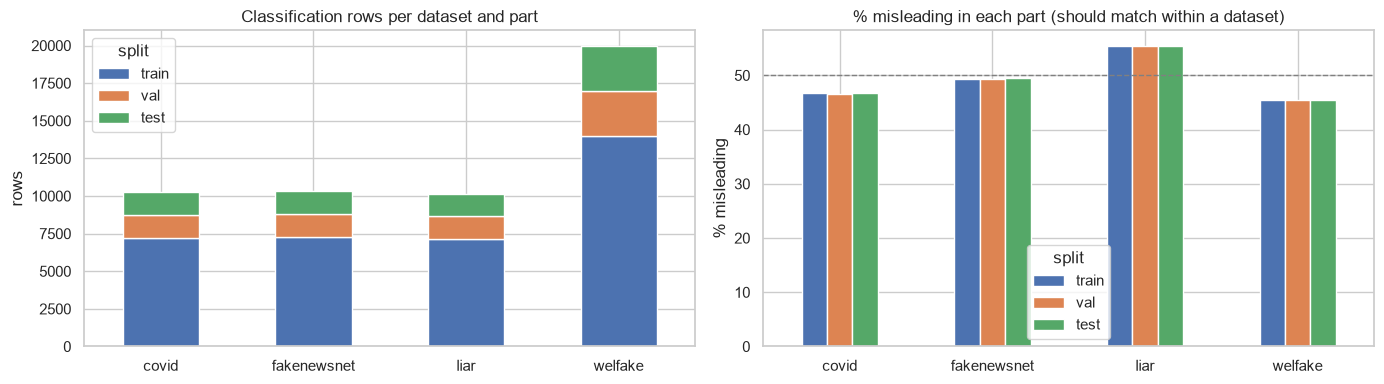

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
summary_wide[mu.SPLITS].plot(kind="bar", stacked=True, ax=axes[0], rot=0,
                             color=["#4C72B0", "#DD8452", "#55A868"])
axes[0].set_title("Classification rows per dataset and part"); axes[0].set_xlabel(""); axes[0].set_ylabel("rows")

pct = summary.pivot(index="dataset", columns="split", values="% misleading")[mu.SPLITS]
pct.plot(kind="bar", ax=axes[1], rot=0, color=["#4C72B0", "#DD8452", "#55A868"])
axes[1].axhline(50, color="grey", lw=1, ls="--")
axes[1].set_title("% misleading in each part (should match within a dataset)")
axes[1].set_xlabel(""); axes[1].set_ylabel("% misleading")
plt.tight_layout(); plt.show()

## 7. Save

Classification files keep the columns the later stages need; `score` is only in the regression
files. Every file has a `split` column so the files can be combined later without losing track.

In [17]:
CLF_COLUMNS = ["row_id", "text", "label", "source_dataset", "sub_source", "n_words", "had_url", "split"]
REG_COLUMNS = ["row_id", "text", "score", "n_words", "split"]

for ds in mu.DATASETS:
    for s, part in clf_splits[ds].items():
        mu.save_csv(part.assign(split=s)[CLF_COLUMNS], mu.split_file(ds, s))
for s, part in reg_splits.items():
    mu.save_csv(part.assign(split=s)[REG_COLUMNS], mu.reg_split_file(s))

Saved   7,114 rows -> liar_train.csv
Saved   1,524 rows -> liar_val.csv
Saved   1,525 rows -> liar_test.csv
Saved  14,000 rows -> welfake_train.csv
Saved   2,999 rows -> welfake_val.csv
Saved   3,001 rows -> welfake_test.csv
Saved   7,195 rows -> covid_train.csv
Saved   1,542 rows -> covid_val.csv
Saved   1,543 rows -> covid_test.csv
Saved   7,243 rows -> fakenewsnet_train.csv
Saved   1,552 rows -> fakenewsnet_val.csv
Saved   1,553 rows -> fakenewsnet_test.csv
Saved   8,953 rows -> liar_reg_train.csv
Saved   1,918 rows -> liar_reg_val.csv
Saved   1,920 rows -> liar_reg_test.csv


**Next stages:** `03_eda` and `04_features` read these files. On Kaggle, save this notebook with
**Save Version → Save & Run All**, then add it as an input to the next notebooks.